In [1]:
from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")

print(imdb)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

c:\Users\User\NUS\DSA NLP\DSA4213_Assignment1\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\User\.cache\huggingface\hub\datasets--stanfordnlp--imdb. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\User\NUS\DSA NLP\DSA4213_Assignment1\.venv\Lib\site-packages\huggingface_hub\file_download

train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

...

unsupervised-00000-of-00001.parquet:   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [2]:
import numpy as np
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# Shuffle official splits reproducibly
train_full = imdb["train"].shuffle(seed=SEED)
test_full = imdb["test"].shuffle(seed=SEED)

# Separate positive and negative examples
train_pos = train_full.filter(lambda x: x["label"] == 1)
train_neg = train_full.filter(lambda x: x["label"] == 0)

test_pos = test_full.filter(lambda x: x["label"] == 1)
test_neg = test_full.filter(lambda x: x["label"] == 0)

# Training: 2,000 per class
train_subset = (
    train_pos.select(range(2000))
    .to_list()
    + train_neg.select(range(2000)).to_list()
)

# Validation: next 500 per class
val_subset = (
    train_pos.select(range(2000, 2500)).to_list()
    + train_neg.select(range(2000, 2500)).to_list()
)

# Test: 500 per class
test_subset = (
    test_pos.select(range(500)).to_list()
    + test_neg.select(range(500)).to_list()
)

random.shuffle(train_subset)
random.shuffle(val_subset)
random.shuffle(test_subset)

print("Training reviews:", len(train_subset))
print("Validation reviews:", len(val_subset))
print("Test reviews:", len(test_subset))

print("\nExample review:")
print(train_subset[0]["text"][:300])

print("\nLabel:", train_subset[0]["label"])

Filter:   0%|          | 0/25000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/25000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/25000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/25000 [00:00<?, ? examples/s]

Training reviews: 4000
Validation reviews: 1000
Test reviews: 1000

Example review:
More than just a "kids' movie", "Holes" looks at how past incidents still affect us today, whether we know about them or not. When teenager Stanley Yelnats III (Shia LeBoeuf) gets sent to a prison camp where he is forced to dig all day long, he discovers a number of things about the camp, and his pe

Label: 1


In [3]:
from collections import Counter

for name, subset in [
    ("Train", train_subset),
    ("Validation", val_subset),
    ("Test", test_subset)
]:
    labels = [item["label"] for item in subset]

    print(f"{name}: {dict(sorted(Counter(labels).items()))}")

Train: {0: 2000, 1: 2000}
Validation: {0: 500, 1: 500}
Test: {0: 500, 1: 500}


In [4]:
import torch
import json
import re
from pathlib import Path

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd

DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

with open(DATA_DIR / "vocab.json", encoding="utf-8") as f:
    word_to_id = json.load(f)

VOCAB_SIZE = len(word_to_id)
PAD_ID = word_to_id["<pad>"]
UNK_ID = word_to_id["<unk>"]

CONTEXT_LENGTH = 32
DEVICE = torch.device("cpu")

print("Vocabulary size:", VOCAB_SIZE)
print("Padding ID:", PAD_ID)
print("Unknown ID:", UNK_ID)
print("Device:", DEVICE)

Vocabulary size: 10000
Padding ID: 0
Unknown ID: 1
Device: cpu


In [5]:
def tokenize_review(text):
    # Replace HTML line breaks with spaces
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.IGNORECASE)

    # Lowercase and tokenize
    tokens = text.strip().lower().split()

    # Convert words to WikiText vocabulary IDs
    token_ids = [
        word_to_id.get(token, UNK_ID)
        for token in tokens
    ]

    return token_ids

In [6]:
sample_review = train_subset[0]["text"]

tokens = tokenize_review(sample_review)

print("Original review:")
print(sample_review[:300])

print("\nFirst 30 token IDs:")
print(tokens[:30])

print("\nTotal tokens:", len(tokens))

unknown_count = sum(t == UNK_ID for t in tokens)

print(
    f"Unknown token percentage: "
    f"{100 * unknown_count / max(len(tokens), 1):.2f}%"
)

Original review:
More than just a "kids' movie", "Holes" looks at how past incidents still affect us today, whether we know about them or not. When teenager Stanley Yelnats III (Shia LeBoeuf) gets sent to a prison camp where he is forced to dig all day long, he discovers a number of things about the camp, and his pe

First 30 token IDs:
[66, 86, 247, 9, 1, 1, 1, 3575, 26, 419, 830, 7308, 300, 5729, 238, 1, 1054, 284, 1087, 79, 98, 49, 1, 62, 8629, 3235, 1, 885, 1, 1]

Total tokens: 113
Unknown token percentage: 23.89%


In [7]:
import sys

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from language_models import (
    LSTMLanguageModel,
    TransformerLanguageModel
)

# Original LSTM from Part I
lstm_model = LSTMLanguageModel(
    vocab_size=VOCAB_SIZE,
    embedding_dim=100,
    hidden_dim=128,
    num_layers=1,
    pad_id=PAD_ID
).to(DEVICE)

lstm_checkpoint = torch.load(
    MODELS_DIR / "lstm_best.pt",
    map_location=DEVICE,
    weights_only=True
)

lstm_model.load_state_dict(
    lstm_checkpoint["model_state_dict"]
)

# Original Transformer from Part I
transformer_model = TransformerLanguageModel(
    vocab_size=VOCAB_SIZE,
    embedding_dim=100,
    num_heads=4,
    num_layers=2,
    ff_dim=256,
    max_seq_length=32,
    dropout=0.1,
    pad_id=PAD_ID
).to(DEVICE)

transformer_checkpoint = torch.load(
    MODELS_DIR / "transformer_best.pt",
    map_location=DEVICE,
    weights_only=True
)

transformer_model.load_state_dict(
    transformer_checkpoint["model_state_dict"]
)

# Freeze both language models
for model in [lstm_model, transformer_model]:
    model.eval()

    for parameter in model.parameters():
        parameter.requires_grad_(False)

print("LSTM loaded and frozen!")
print("Transformer loaded and frozen!")

LSTM loaded and frozen!
Transformer loaded and frozen!


In [8]:
import numpy as np

MAX_REVIEW_TOKENS = 256

@torch.inference_mode()
def extract_representation(model, token_ids, model_type):

    # Truncate long reviews
    token_ids = token_ids[:MAX_REVIEW_TOKENS]

    # Handle empty reviews
    if len(token_ids) == 0:
        token_ids = [UNK_ID]

    representations = []

    # Process chunks of at most 32 tokens
    for start in range(0, len(token_ids), CONTEXT_LENGTH):

        chunk = token_ids[start:start + CONTEXT_LENGTH]

        x = torch.tensor(
            [chunk],
            dtype=torch.long,
            device=DEVICE
        )

        if model_type == "lstm":

            embedded = model.embedding(x)

            output, (hidden, cell) = model.lstm(embedded)

            # Shape: (sequence_length, 128)
            token_states = output[0]

        elif model_type == "transformer":

            seq_length = x.shape[1]

            positions = torch.arange(
                seq_length,
                device=DEVICE
            )

            embedded = (
                model.token_embedding(x)
                + model.position_embedding(positions).unsqueeze(0)
            )

            causal_mask = torch.triu(
                torch.ones(
                    seq_length,
                    seq_length,
                    dtype=torch.bool,
                    device=DEVICE
                ),
                diagonal=1
            )

            output = model.transformer(
                embedded,
                mask=causal_mask
            )

            # Shape: (sequence_length, 100)
            token_states = output[0]

        else:
            raise ValueError("Unknown model type")

        representations.append(token_states.cpu())

    # Combine all valid token states
    all_states = torch.cat(representations, dim=0)

    # Mean pooling across tokens
    review_vector = all_states.mean(dim=0)

    return review_vector.numpy()

In [9]:
sample_review = train_subset[0]["text"]
sample_ids = tokenize_review(sample_review)

lstm_vector = extract_representation(
    lstm_model,
    sample_ids,
    "lstm"
)

transformer_vector = extract_representation(
    transformer_model,
    sample_ids,
    "transformer"
)

print("Original review tokens:", len(sample_ids))
print("Tokens used:", min(len(sample_ids), MAX_REVIEW_TOKENS))

print("\nLSTM representation shape:", lstm_vector.shape)
print("Transformer representation shape:", transformer_vector.shape)

print("\nLSTM contains NaN:", np.isnan(lstm_vector).any())
print("Transformer contains NaN:", np.isnan(transformer_vector).any())

assert lstm_vector.shape == (128,)
assert transformer_vector.shape == (100,)

assert np.isfinite(lstm_vector).all()
assert np.isfinite(transformer_vector).all()

print("\nRepresentation extraction successful!")

Original review tokens: 113
Tokens used: 113

LSTM representation shape: (128,)
Transformer representation shape: (100,)

LSTM contains NaN: False
Transformer contains NaN: False

Representation extraction successful!


In [10]:
from tqdm.auto import tqdm
import numpy as np
import time

def extract_dataset_features(model, dataset_subset, model_type):
    features = []
    labels = []

    start_time = time.perf_counter()

    for item in tqdm(
        dataset_subset,
        desc=f"Extracting {model_type} features"
    ):
        token_ids = tokenize_review(item["text"])

        vector = extract_representation(
            model,
            token_ids,
            model_type
        )

        features.append(vector)
        labels.append(item["label"])

    elapsed = time.perf_counter() - start_time

    X = np.stack(features).astype(np.float32)
    y = np.array(labels, dtype=np.int64)

    print(f"\n{model_type.upper()} extraction completed!")
    print("Feature shape:", X.shape)
    print("Label shape:", y.shape)
    print(f"Extraction time: {elapsed:.2f} seconds")

    return X, y

In [11]:
X_train_lstm, y_train = extract_dataset_features(
    lstm_model,
    train_subset,
    "lstm"
)

X_val_lstm, y_val = extract_dataset_features(
    lstm_model,
    val_subset,
    "lstm"
)

X_test_lstm, y_test = extract_dataset_features(
    lstm_model,
    test_subset,
    "lstm"
)

print("\nLSTM feature matrices:")
print("Training:", X_train_lstm.shape)
print("Validation:", X_val_lstm.shape)
print("Test:", X_test_lstm.shape)

Extracting lstm features:   0%|          | 0/4000 [00:00<?, ?it/s]


LSTM extraction completed!
Feature shape: (4000, 128)
Label shape: (4000,)
Extraction time: 18.31 seconds


Extracting lstm features:   0%|          | 0/1000 [00:00<?, ?it/s]


LSTM extraction completed!
Feature shape: (1000, 128)
Label shape: (1000,)
Extraction time: 4.10 seconds


Extracting lstm features:   0%|          | 0/1000 [00:00<?, ?it/s]


LSTM extraction completed!
Feature shape: (1000, 128)
Label shape: (1000,)
Extraction time: 3.82 seconds

LSTM feature matrices:
Training: (4000, 128)
Validation: (1000, 128)
Test: (1000, 128)


In [12]:
RESULTS_DIR.mkdir(exist_ok=True)

np.savez_compressed(
    RESULTS_DIR / "imdb_lstm_features.npz",
    X_train=X_train_lstm,
    X_val=X_val_lstm,
    X_test=X_test_lstm,
    y_train=y_train,
    y_val=y_val,
    y_test=y_test
)

print("LSTM features saved successfully!")

LSTM features saved successfully!


In [13]:
X_train_transformer, y_train_t = extract_dataset_features(
    transformer_model,
    train_subset,
    "transformer"
)

X_val_transformer, y_val_t = extract_dataset_features(
    transformer_model,
    val_subset,
    "transformer"
)

X_test_transformer, y_test_t = extract_dataset_features(
    transformer_model,
    test_subset,
    "transformer"
)

print("\nTransformer feature matrices:")
print("Training:", X_train_transformer.shape)
print("Validation:", X_val_transformer.shape)
print("Test:", X_test_transformer.shape)

Extracting transformer features:   0%|          | 0/4000 [00:00<?, ?it/s]


TRANSFORMER extraction completed!
Feature shape: (4000, 100)
Label shape: (4000,)
Extraction time: 34.38 seconds


Extracting transformer features:   0%|          | 0/1000 [00:00<?, ?it/s]


TRANSFORMER extraction completed!
Feature shape: (1000, 100)
Label shape: (1000,)
Extraction time: 10.15 seconds


Extracting transformer features:   0%|          | 0/1000 [00:00<?, ?it/s]


TRANSFORMER extraction completed!
Feature shape: (1000, 100)
Label shape: (1000,)
Extraction time: 9.84 seconds

Transformer feature matrices:
Training: (4000, 100)
Validation: (1000, 100)
Test: (1000, 100)


In [14]:
assert np.array_equal(y_train, y_train_t)
assert np.array_equal(y_val, y_val_t)
assert np.array_equal(y_test, y_test_t)

print("Training labels match!")
print("Validation labels match!")
print("Test labels match!")

print("\nBoth models use identical examples and labels.")

Training labels match!
Validation labels match!
Test labels match!

Both models use identical examples and labels.


In [15]:
np.savez_compressed(
    RESULTS_DIR / "imdb_transformer_features.npz",
    X_train=X_train_transformer,
    X_val=X_val_transformer,
    X_test=X_test_transformer,
    y_train=y_train_t,
    y_val=y_val_t,
    y_test=y_test_t
)

print("Transformer features saved successfully!")

Transformer features saved successfully!


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

SEED = 42

# Same classifier family and hyperparameters
def create_classifier():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            random_state=SEED
        )
    )

# Train LSTM classifier
lstm_classifier = create_classifier()
lstm_classifier.fit(X_train_lstm, y_train)

# Train Transformer classifier
transformer_classifier = create_classifier()
transformer_classifier.fit(
    X_train_transformer,
    y_train
)

print("LSTM classifier trained!")
print("Transformer classifier trained!")

LSTM classifier trained!
Transformer classifier trained!


In [17]:
# Validation predictions
lstm_val_pred = lstm_classifier.predict(X_val_lstm)

transformer_val_pred = transformer_classifier.predict(
    X_val_transformer
)

validation_results = pd.DataFrame([
    {
        "Model": "LSTM",
        "Accuracy": accuracy_score(y_val, lstm_val_pred),
        "Macro-F1": f1_score(
            y_val, lstm_val_pred, average="macro"
        )
    },
    {
        "Model": "Transformer",
        "Accuracy": accuracy_score(
            y_val, transformer_val_pred
        ),
        "Macro-F1": f1_score(
            y_val, transformer_val_pred,
            average="macro"
        )
    }
])

print(validation_results.to_string(index=False))

      Model  Accuracy  Macro-F1
       LSTM     0.686   0.68598
Transformer     0.687   0.68693


In [18]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import pandas as pd

# Predict test labels
lstm_test_pred = lstm_classifier.predict(
    X_test_lstm
)

transformer_test_pred = transformer_classifier.predict(
    X_test_transformer
)

# Compare performance
test_results = pd.DataFrame([
    {
        "Model": "LSTM",
        "Accuracy": accuracy_score(
            y_test, lstm_test_pred
        ),
        "Macro-F1": f1_score(
            y_test,
            lstm_test_pred,
            average="macro"
        )
    },
    {
        "Model": "Transformer",
        "Accuracy": accuracy_score(
            y_test, transformer_test_pred
        ),
        "Macro-F1": f1_score(
            y_test,
            transformer_test_pred,
            average="macro"
        )
    }
])

print("FINAL TEST RESULTS")
print(test_results.to_string(index=False))

FINAL TEST RESULTS
      Model  Accuracy  Macro-F1
       LSTM     0.672  0.671999
Transformer     0.681  0.680992


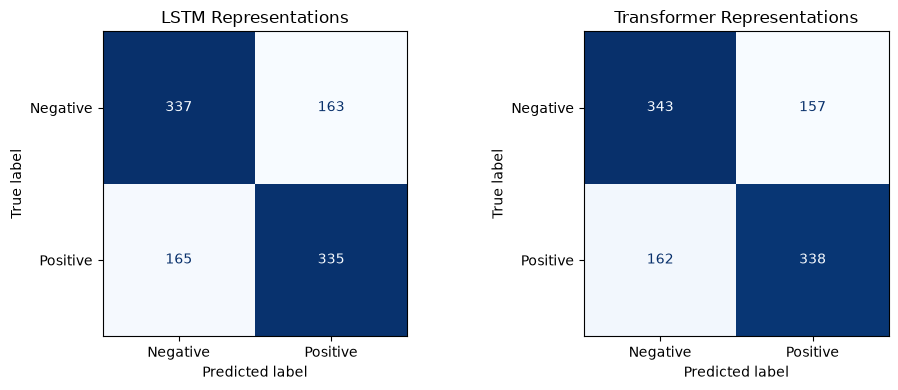

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lstm_test_pred,
    display_labels=["Negative", "Positive"],
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)

axes[0].set_title("LSTM Representations")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    transformer_test_pred,
    display_labels=["Negative", "Positive"],
    ax=axes[1],
    cmap="Blues",
    colorbar=False
)

axes[1].set_title("Transformer Representations")

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "downstream_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [20]:
import numpy as np

both_wrong = np.where(
    (lstm_test_pred != y_test) &
    (transformer_test_pred != y_test)
)[0]

lstm_only_correct = np.where(
    (lstm_test_pred == y_test) &
    (transformer_test_pred != y_test)
)[0]

transformer_only_correct = np.where(
    (transformer_test_pred == y_test) &
    (lstm_test_pred != y_test)
)[0]

both_correct = np.where(
    (lstm_test_pred == y_test) &
    (transformer_test_pred == y_test)
)[0]

print("Both models correct:", len(both_correct))
print("Both models wrong:", len(both_wrong))
print("Only LSTM correct:", len(lstm_only_correct))
print("Only Transformer correct:", len(transformer_only_correct))

assert (
    len(both_correct)
    + len(both_wrong)
    + len(lstm_only_correct)
    + len(transformer_only_correct)
) == len(y_test)

print("\nError categories verified!")

Both models correct: 560
Both models wrong: 207
Only LSTM correct: 112
Only Transformer correct: 121

Error categories verified!


In [21]:
def show_examples(indices, category, n=3):
    print("\n" + "=" * 70)
    print(category)
    print("=" * 70)

    for idx in indices[:n]:
        idx = int(idx)

        review = test_subset[idx]["text"]

        print(f"\nReview index: {idx}")
        print("True label:", "Positive" if y_test[idx] == 1 else "Negative")
        print("LSTM prediction:", "Positive" if lstm_test_pred[idx] == 1 else "Negative")
        print("Transformer prediction:", "Positive" if transformer_test_pred[idx] == 1 else "Negative")

        print("\nReview:")
        print(review[:700])
        print("-" * 70)


show_examples(both_wrong, "BOTH MODELS WRONG")
show_examples(lstm_only_correct, "ONLY LSTM CORRECT")
show_examples(transformer_only_correct, "ONLY TRANSFORMER CORRECT")


BOTH MODELS WRONG

Review index: 9
True label: Negative
LSTM prediction: Positive
Transformer prediction: Positive

Review:
This is truly a re-make that should never have gotten out of the stable. It has two casts that are acting in entirely different strata. At the top of their game are Joan Plowright and Maximillian Schell. Every nuance of the Franks is in plain sight. at the rock bottom are Melissa Gilbert and Doris Roberts. I cannot imagine how Schell and Plowright manage to play so well when Gilbert and Roberts are working their anti-magic. Gilbert ruins every scene she's in. It's like Father Knows Best in the Ghetto. She's Ann Frank light. Her run at Helen Keller was thin but not awful. This is sacrilege. Doris Roberts makes Mrs. Van Damm merely annoying. She is a completely inappropriate choice to play the
----------------------------------------------------------------------

Review index: 10
True label: Positive
LSTM prediction: Negative
Transformer prediction: Negative

Revi

In [22]:
import json
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

downstream_results = {
    "dataset": "IMDb",
    "train_size": 4000,
    "validation_size": 1000,
    "test_size": 1000,
    "max_review_tokens": 256,
    "context_length": 32,
    "pooling": "mean",
    "classifier": "Logistic Regression",
    "random_seed": 42,

    "lstm": {
        "representation_dim": 128,
        "test_accuracy": float(
            accuracy_score(y_test, lstm_test_pred)
        ),
        "test_macro_f1": float(
            f1_score(y_test, lstm_test_pred, average="macro")
        )
    },

    "transformer": {
        "representation_dim": 100,
        "test_accuracy": float(
            accuracy_score(y_test, transformer_test_pred)
        ),
        "test_macro_f1": float(
            f1_score(y_test, transformer_test_pred, average="macro")
        )
    },

    "error_analysis": {
        "both_correct": len(both_correct),
        "both_wrong": len(both_wrong),
        "only_lstm_correct": len(lstm_only_correct),
        "only_transformer_correct": len(transformer_only_correct)
    }
}

output_path = RESULTS_DIR / "downstream_results.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(downstream_results, f, indent=2)

print("Part III results saved successfully!")
print("File:", output_path)

Part III results saved successfully!
File: c:\Users\User\NUS\DSA NLP\DSA4213_Assignment1\results\downstream_results.json


In [23]:
print("File exists:", output_path.exists())

with open(output_path, encoding="utf-8") as f:
    saved_results = json.load(f)

print("LSTM accuracy:", saved_results["lstm"]["test_accuracy"])
print("Transformer accuracy:", saved_results["transformer"]["test_accuracy"])

File exists: True
LSTM accuracy: 0.672
Transformer accuracy: 0.681
